<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%9612.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision.models import resnet18, resnet34

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Підготовка даних CIFAR10

6 9 9 4 1 1 2 7 8 3 

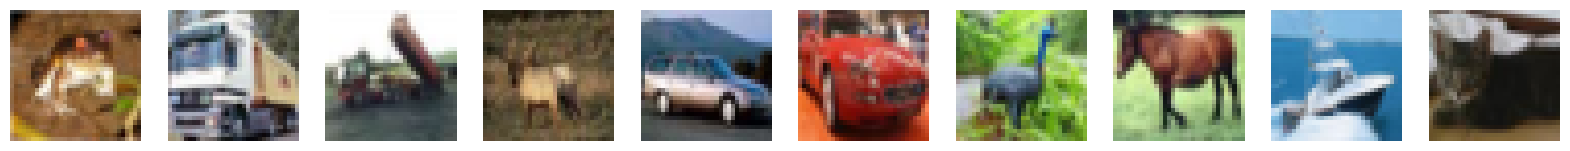


torch.Size([10000, 3, 32, 32]) torch.Size([2000, 3, 32, 32]) torch.Size([2000, 3, 32, 32])


In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

X_all = torch.FloatTensor(CIFAR_train.data) / 255.
y_all = torch.LongTensor(CIFAR_train.targets)
X_test_all = torch.FloatTensor(CIFAR_test.data) / 255.
y_test_all = torch.LongTensor(CIFAR_test.targets)

plt.figure(figsize=(20, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_all[i])
    plt.axis('off')
    print(y_all[i].item(), end=' ')
plt.show()

X_all = X_all.permute(0, 3, 1, 2)
X_test_all = X_test_all.permute(0, 3, 1, 2)

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_all), generator=generator)
test_permutation = torch.randperm(len(X_test_all), generator=generator)

X_train, y_train = X_all[permutation[:10000]], y_all[permutation[:10000]]
X_val, y_val = X_all[permutation[10000:12000]], y_all[permutation[10000:12000]]
X_test, y_test = X_test_all[test_permutation[:2000]], y_test_all[test_permutation[:2000]]

print()
print(X_train.shape, X_val.shape, X_test.shape)

Дані готуються так, як у теорії: значення ділиться на 255, а розмірності переставляються у формат `кількість × канали × висота × ширина`. Для скорочення часу навчання використовується підвибірка: 10 000 зображень для навчання, 2000 для валідації (з тренувальної частини) та 2000 для фінальної перевірки (з тестового набору). Графіки на кожній епосі будуються за валідаційною вибіркою, а підсумкова точність наводиться на окремій тестовій.

# Функції навчання та побудови графіків

In [ ]:
sns.set_style("darkgrid")
sns.set(rc={'figure.figsize': (15, 6)})

accuracies = {}
losses = {}
finals = {}

def train(net, X_train, y_train, X_val, y_val, batch_size=256, epoch_num=5, epoch_info_show=1,
          weight_decay=0, augment=False, verbose=True):
    net = net.to(device)
    loss = torch.nn.CrossEntropyLoss().to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=1.0e-3, weight_decay=weight_decay)

    t = time.time()
    val_accuracy_history = []
    val_loss_history = []
    epoch_times = []
    X_val = X_val.to(device)
    y_val = y_val.to(device)

    for epoch in range(1, epoch_num + 1):
        epoch_start = time.time()
        order = np.random.permutation(len(X_train))
        for start_index in range(0, len(X_train), batch_size):
            optimizer.zero_grad()
            net.train()

            batch_indexes = order[start_index:start_index + batch_size]

            X_batch = X_train[batch_indexes].to(device)
            y_batch = y_train[batch_indexes].to(device)
            if augment:
                X_batch = augment_batch(X_batch)

            preds = net.forward(X_batch)

            loss_value = loss(preds, y_batch)
            loss_value.backward()

            optimizer.step()

        net.eval()
        with torch.no_grad():
            val_preds = net.forward(X_val)
        val_loss_history.append(loss(val_preds, y_val).item())
        accuracy = (val_preds.argmax(dim=1) == y_val).float().mean().item()
        val_accuracy_history.append(accuracy)
        epoch_times.append(time.time() - epoch_start)

        if verbose and epoch % epoch_info_show == 0:
            print('Epoch: {} Time: {} Accuracy: {:.4f}'.format(
                epoch, time.strftime("%H:%M:%S", time.gmtime(time.time() - t)), accuracy))

    return net, val_accuracy_history, val_loss_history, float(np.mean(epoch_times))

def augment_batch(x):
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = torch.nn.functional.pad(x, (4, 4, 4, 4), mode='reflect')
    dx, dy = np.random.randint(0, 9, size=2)
    return padded[:, :, dy:dy + 32, dx:dx + 32]

def run(name, net, X_test=X_test, y_test=y_test, **kwargs):
    print('==', name)
    net, acc_history, loss_history, sec_per_epoch = train(net, X_train, y_train, X_val, y_val, **kwargs)
    net.eval()
    with torch.no_grad():
        test_logits = net.forward(X_test.to(device)).cpu()
    test_accuracy = (test_logits.argmax(dim=1) == y_test).float().mean().item()
    accuracies[name] = acc_history
    losses[name] = loss_history
    finals[name] = {
        'параметрів': sum(p.numel() for p in net.parameters()),
        'best val acc': max(acc_history),
        'val acc (остання)': acc_history[-1],
        'val loss (мін)': min(loss_history),
        'test acc': test_accuracy,
        'с / епоху': sec_per_epoch,
        'logits': test_logits,
    }
    print('test accuracy: {:.4f}'.format(test_accuracy))
    del net

def acc_loss_graph(accuracies, losses, net_list):
    fig, (ax1, ax2) = plt.subplots(1, 2)

    for experiment_id in net_list:
        ax1.plot(accuracies[experiment_id], label=experiment_id)
    ax1.legend()
    ax1.set_title('Validation Accuracy')
    fig.tight_layout()

    for experiment_id in net_list:
        ax2.plot(losses[experiment_id], label=experiment_id)
    ax2.legend()
    ax2.set_title('Validation Loss')

    fig.tight_layout()
    plt.show()

def results_table(names):
    return pd.DataFrame({n: {k: v for k, v in finals[n].items() if k != 'logits'} for n in names}).T

Функція `train` повторює код з теорії: навчання батчами, Adam зі швидкістю 1e-3, `net.train()` під час навчання та `net.eval()` разом із `torch.no_grad()` під час перевірки. Додано лише вимірювання часу епохи та необов'язкову аугментацію. Функція `run` запускає навчання та записує історію й підсумкову точність на тестовій вибірці. Для всіх експериментів, якщо не вказано інше, використовується 5 епох, щоб порівняння були коректними.

# Моделі з теоретичної частини

In [ ]:
class CIFARNet(torch.nn.Module):
    def __init__(self):
        super(CIFARNet, self).__init__()
        self.batch_norm0 = torch.nn.BatchNorm2d(3)

        self.conv1 = torch.nn.Conv2d(3, 16, 3, padding=1)
        self.act1 = torch.nn.ReLU()
        self.batch_norm1 = torch.nn.BatchNorm2d(16)
        self.pool1 = torch.nn.MaxPool2d(2, 2)

        self.conv2 = torch.nn.Conv2d(16, 32, 3, padding=1)
        self.act2 = torch.nn.ReLU()
        self.batch_norm2 = torch.nn.BatchNorm2d(32)
        self.pool2 = torch.nn.MaxPool2d(2, 2)

        self.conv3 = torch.nn.Conv2d(32, 64, 3, padding=1)
        self.act3 = torch.nn.ReLU()
        self.batch_norm3 = torch.nn.BatchNorm2d(64)

        self.fc1 = torch.nn.Linear(8 * 8 * 64, 256)
        self.act4 = torch.nn.Tanh()
        self.batch_norm4 = torch.nn.BatchNorm1d(256)

        self.fc2 = torch.nn.Linear(256, 64)
        self.act5 = torch.nn.Tanh()
        self.batch_norm5 = torch.nn.BatchNorm1d(64)

        self.fc3 = torch.nn.Linear(64, 10)

    def forward(self, x):
        x = self.batch_norm0(x)

        x = self.conv1(x)
        x = self.act1(x)
        x = self.batch_norm1(x)
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.act2(x)
        x = self.batch_norm2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        x = self.act3(x)
        x = self.batch_norm3(x)

        x = x.view(x.size(0), x.size(1) * x.size(2) * x.size(3))
        x = self.fc1(x)
        x = self.act4(x)
        x = self.batch_norm4(x)

        x = self.fc2(x)
        x = self.act5(x)
        x = self.batch_norm5(x)

        x = self.fc3(x)

        return x

class LambdaLayer(torch.nn.Module):
    def __init__(self, lambd):
        super(LambdaLayer, self).__init__()
        self.lambd = lambd

    def forward(self, x):
        return self.lambd(x)

class BasicBlock(torch.nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, option='A',
                 use_batch_norm=True, use_drop_out=False, d_out_p=0.5):
        super(BasicBlock, self).__init__()
        self.use_batch_norm = use_batch_norm
        self.use_drop_out = use_drop_out
        self.d_out_p = d_out_p
        self.act = torch.nn.ReLU()

        self.conv1 = torch.nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = torch.nn.BatchNorm2d(planes)
        self.d_out1 = torch.nn.Dropout2d(d_out_p)
        self.conv2 = torch.nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = torch.nn.BatchNorm2d(planes)
        self.d_out2 = torch.nn.Dropout2d(d_out_p)

        self.shortcut = torch.nn.Sequential()
        if stride != 1 or in_planes != planes:
            if option == 'A':
                self.shortcut = LambdaLayer(lambda x: torch.nn.functional.pad(
                    x[:, :, ::2, ::2], (0, 0, 0, 0, planes // 4, planes // 4), "constant", 0))
            elif option == 'B':
                self.shortcut = torch.nn.Sequential(
                    torch.nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                    torch.nn.BatchNorm2d(self.expansion * planes)
                )

    def forward(self, x):
        out = self.conv1(x)
        if self.use_batch_norm:
            out = self.bn1(out)
        if self.use_drop_out:
            out = self.d_out1(out)
        out = self.act(out)
        out = self.conv2(out)

        if self.use_batch_norm:
            out = self.bn2(out)
        if self.use_drop_out:
            out = self.d_out2(out)

        out += self.shortcut(x)
        out = self.act(out)
        return out

class ResNet(torch.nn.Module):
    def __init__(self, block, num_blocks, num_classes=10,
                 use_batch_norm=True, use_drop_out=False, d_out_p=0.5):
        super(ResNet, self).__init__()
        self.use_batch_norm = use_batch_norm
        self.use_drop_out = use_drop_out
        self.d_out_p = d_out_p
        self.in_planes = 16
        self.act = torch.nn.ReLU()

        self.conv1 = torch.nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = torch.nn.BatchNorm2d(16)
        self.d_out1 = torch.nn.Dropout2d(d_out_p)
        self.layer1 = self._make_layer(block, 16, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 32, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 64, num_blocks[2], stride=2)
        self.linear = torch.nn.Linear(64 * block.expansion, num_classes)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for stride in strides:
            layers.append(block(self.in_planes, planes, stride,
                                use_batch_norm=self.use_batch_norm,
                                use_drop_out=self.use_drop_out,
                                d_out_p=self.d_out_p))
            self.in_planes = planes * block.expansion
        return torch.nn.Sequential(*layers)

    def forward(self, x):
        out = self.conv1(x)
        if self.use_batch_norm:
            out = self.bn1(out)
        if self.use_drop_out:
            out = self.d_out1(out)
        out = self.act(out)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = torch.nn.functional.avg_pool2d(out, out.size()[3])
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

def resnet110():
    return ResNet(BasicBlock, [18, 18, 18])

def resnet110_no_bn():
    return ResNet(BasicBlock, [18, 18, 18], use_batch_norm=False)

def resnet110_d_out15():
    return ResNet(BasicBlock, [18, 18, 18], use_drop_out=True, d_out_p=0.15)

def resnet20():
    return ResNet(BasicBlock, [3, 3, 3])

def resnet20_d_out(p):
    return ResNet(BasicBlock, [3, 3, 3], use_drop_out=True, d_out_p=p)

for name, factory in (('CIFARNet', CIFARNet), ('ResNet20', resnet20), ('ResNet110', resnet110)):
    model = factory()
    print(name, 'параметрів:', sum(p.numel() for p in model.parameters()),
          '| вихід:', tuple(model(torch.randn(2, 3, 32, 32)).shape))

CIFARNet параметрів: 1090384 | вихід: (2, 10)
ResNet20 параметрів: 269722 | вихід: (2, 10)


ResNet110 параметрів: 1727962 | вихід: (2, 10)


Класи `CIFARNet`, `BasicBlock` (залишковий блок) і `ResNet` взято з теорії. Блок має два згорткові шари 3 на 3 без зміщення (`bias=False`, бо зміщення в нього вже включає `BatchNorm`), пакетну нормалізацію, необов'язковий Dropout і коротке з'єднання. Якщо розмірність змінюється, коротке з'єднання робить варіант A (пропуск пікселів і доповнення нулями без додаткових параметрів) або варіант B (згортка 1 на 1). Мережа ResNet20 складається з 9 залишкових блоків (3 + 3 + 3), а ResNet110 з 54 (18 + 18 + 18). Шари мають 16, 32 і 64 канали, а перед повнозв'язним шаром виконується усереднювальний пулінг. До класу `ResNet` додано множник `block.expansion` у розмірі вихідного шару, щоб він працював і з блоком bottleneck із завдання 5.

# Завдання 1. Реалізація мереж з теорії

> 1. Реалізуйте нейронні мережі наведені в теоретичному матеріалі та проаналізуйте отриманий результат.

== cifar_net


Epoch: 1 Time: 00:00:03 Accuracy: 0.4500


Epoch: 2 Time: 00:00:06 Accuracy: 0.5565


Epoch: 3 Time: 00:00:09 Accuracy: 0.5705


Epoch: 4 Time: 00:00:12 Accuracy: 0.5815


Epoch: 5 Time: 00:00:15 Accuracy: 0.5835
test accuracy: 0.5975


... (9 outputs left out)

Epoch: 3 Time: 00:01:37 Accuracy: 0.4150


Epoch: 4 Time: 00:02:10 Accuracy: 0.2910


Epoch: 5 Time: 00:02:43 Accuracy: 0.4565


test accuracy: 0.4665


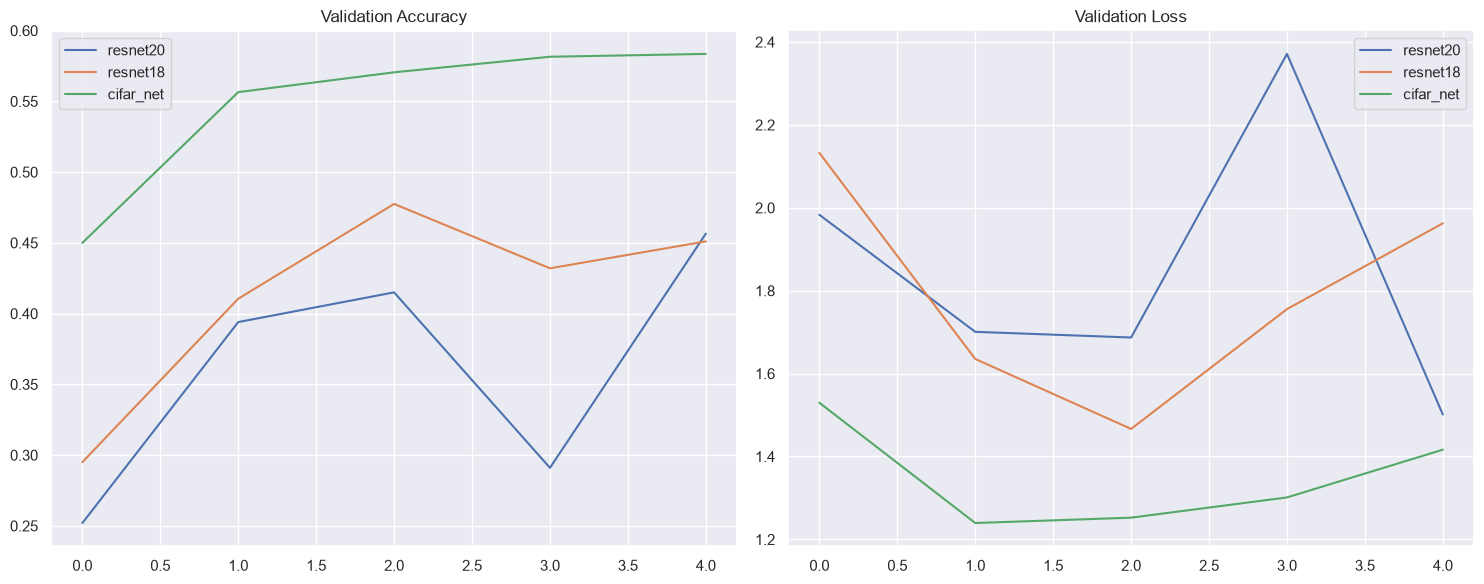

           параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
cifar_net   1090384.0        0.5835             0.5835          1.2395    0.5975     3.1784
resnet18   11181642.0        0.4775             0.4510          1.4665    0.4610    67.3609
resnet20     269722.0        0.4565             0.4565          1.5013    0.4665    32.6309


In [ ]:
run('cifar_net', CIFARNet())
run('resnet18', resnet18(num_classes=10))
run('resnet20', resnet20())

acc_loss_graph(accuracies, losses, ['resnet20', 'resnet18', 'cifar_net'])
print(results_table(['cifar_net', 'resnet18', 'resnet20']).round(4).to_string())

**Результат.** За однакових 5 епох на підвибірці з 10 000 зображень найкращий результат дає найпростіша мережа CIFARNet: test accuracy 0.598 (validation 0.584) при 3 с на епоху. ResNet18 з torchvision дає 0.461 (11.2 млн параметрів, 67 с на епоху), ResNet20 0.467 (0.27 млн параметрів, 33 с на епоху). Тобто глибші залишкові мережі тут не виграють. Причина в умовах експерименту: даних мало (10 000), а навчання дуже коротке, тож глибокі мережі ще не встигли навчитись. Для CIFARNet із батчем 256 і 5 епохами вистачає: вона має пакетну нормалізацію, вхідний шар нормалізації та лише 3 згорткові шари, тому збігається швидше. ResNet18 із теорії створена для зображень ImageNet 224 на 224, тому на зображеннях 32 на 32 вона швидко стискає розмір карт ознак і працює гірше за спеціальну ResNet20 для CIFAR10 за 40 разів меншої кількості параметрів і вдвічі меншого часу епохи (різниця 0.467 проти 0.461 лежить у межах випадкового розкиду). Усі результати нижчі, ніж у роботі №10 (0.748 для мережі CIFARNet-типу), бо там було 45 000 зображень і довше навчання.

# Завдання 6. Порівняння з resnet18 з torchvision

> 6. З бібліотеки torchvision (ставиться разом з pytorch), можна імпортувати ResNet18 командою "from torchvision.models import resnet18". Порівняйте результати resnet18, або інших мереж із Вашою мережею. Яка мережа дає кращий результат?

== resnet34


Epoch: 1 Time: 00:01:18 Accuracy: 0.2390


Epoch: 2 Time: 00:02:37 Accuracy: 0.4010


Epoch: 3 Time: 00:03:56 Accuracy: 0.4380


Epoch: 4 Time: 00:05:15 Accuracy: 0.3915


Epoch: 5 Time: 00:06:35 Accuracy: 0.4365


test accuracy: 0.4585
           параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
cifar_net   1090384.0        0.5835             0.5835          1.2395    0.5975     3.1784
resnet18   11181642.0        0.4775             0.4510          1.4665    0.4610    67.3609
resnet34   21289802.0        0.4380             0.4365          1.5670    0.4585    79.0096
resnet20     269722.0        0.4565             0.4565          1.5013    0.4665    32.6309


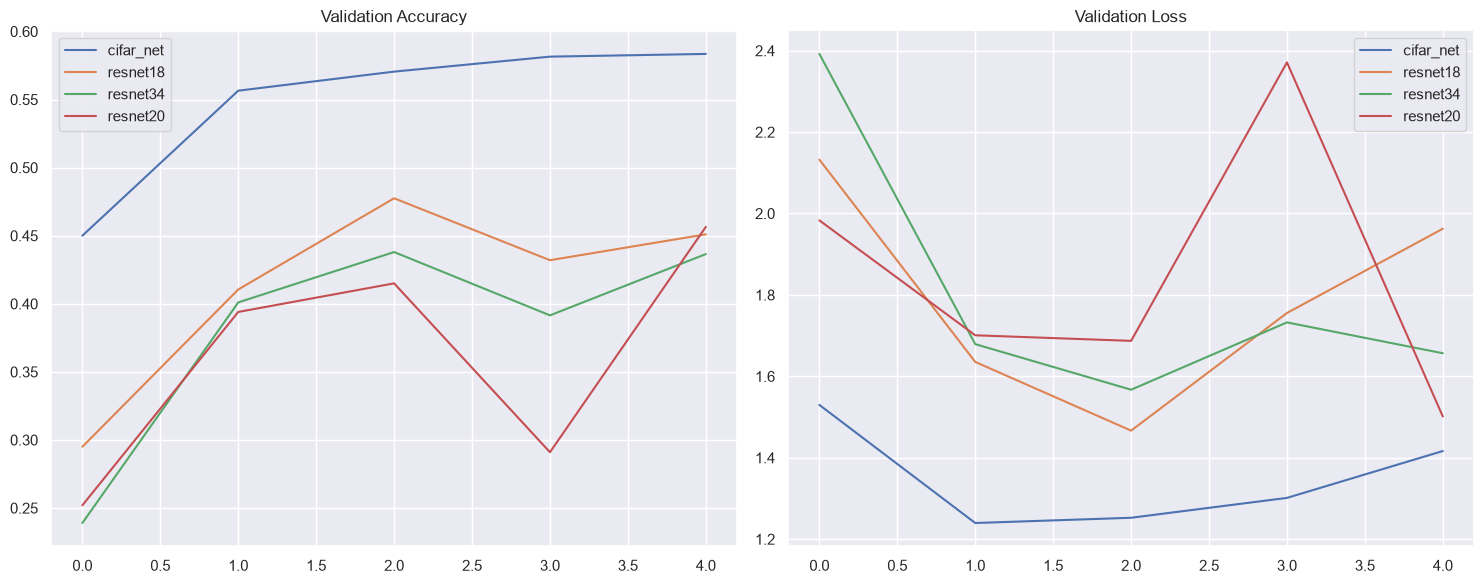

In [ ]:
run('resnet34', resnet34(num_classes=10))
print(results_table(['cifar_net', 'resnet18', 'resnet34', 'resnet20']).round(4).to_string())
acc_loss_graph(accuracies, losses, ['cifar_net', 'resnet18', 'resnet34', 'resnet20'])

**Відповідь.** Серед порівняних мереж кращий результат на тесті дала CIFARNet (0.598), далі ResNet20 (0.467), ResNet18 (0.461) і ResNet34 (0.459). Збільшення глибини ImageNet-ResNet з 18 до 34 шарів (21 млн параметрів, 79 с на епоху) нічого не дало, а навіть трохи погіршило validation accuracy (0.438 проти 0.478). Власна реалізація ResNet20 з теорії з 0.27 млн параметрів дає результат на рівні ResNet18, що в 40 разів більша, і працює вдвічі швидше. Тому для CIFAR10 краще використовувати архітектуру, розроблену для маленьких зображень, а не ImageNet-версію. Різниці між ResNet18, ResNet20 і ResNet34 малі, і одним запуском їх відрізнити не можна.

# Завдання 4. Інші вбудовані моделі PyTorch

> 4. Спробуйте інші вбудовані в PyTorch моделі. Повний список моделей можна знайти у документації https://pytorch.org/docs/stable/torchvision/models.html.

Із вбудованих у PyTorch моделей перевірено ResNet18 та ResNet34 (результати наведені у попередньому завданні). Мережі з бібліотеки `torchvision.models` створюються готовою командою, наприклад `resnet18(num_classes=10)`, де параметр `num_classes` задає кількість виходів останнього шару. Без цього параметра мережа має 1000 виходів (класи ImageNet), що працює, але є зайвим для CIFAR10. Обидві моделі створені для зображень 224 на 224, тому на малих зображеннях CIFAR10 вони не мають переваги над спеціалізованою ResNet20. Важчі мережі (наприклад, MobileNet, який за оцінкою на CPU навчається близько 16 хвилин на епоху) для цієї роботи не запускались через обмеження часу.

# Завдання 7. Власна реалізація ResNet20

> 7. Спробуйте, користуючись описом архітектури з оригінальної статті (https://arxiv.org/pdf/1512.03385.pdf), написати власну реалізацію ResNet20. Якщо виникнуть сумніви, можна звіритися з кодом з https://github.com/akamaster/pytorch_resnet_cifar10. Чи вдалося побити resnet18?

In [ ]:
class MyResNet20(torch.nn.Module):
    def __init__(self, num_classes=10):
        super(MyResNet20, self).__init__()
        self.conv = torch.nn.Sequential(
            torch.nn.Conv2d(3, 16, 3, padding=1, bias=False), torch.nn.BatchNorm2d(16), torch.nn.ReLU())

        def stage(in_c, out_c, stride):
            blocks = []
            for i in range(3):
                blocks.append(BasicBlock(in_c if i == 0 else out_c, out_c, stride if i == 0 else 1))
            return torch.nn.Sequential(*blocks)

        self.stages = torch.nn.Sequential(stage(16, 16, 1), stage(16, 32, 2), stage(32, 64, 2))
        self.fc = torch.nn.Linear(64, num_classes)

    def forward(self, x):
        x = self.stages(self.conv(x))
        x = torch.nn.functional.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

my_net = MyResNet20()
print("Параметрів у власній реалізації:", sum(p.numel() for p in my_net.parameters()))
print("Параметрів у ResNet20 з теорії:  ", sum(p.numel() for p in resnet20().parameters()))
print("Параметрів у resnet18:           ", sum(p.numel() for p in resnet18(num_classes=10).parameters()))

run('resnet20 (власна)', MyResNet20())
print(results_table(['resnet18', 'resnet20', 'resnet20 (власна)']).round(4).to_string())

Параметрів у власній реалізації: 269722
Параметрів у ResNet20 з теорії:   269722


Параметрів у resnet18:            11181642
== resnet20 (власна)


Epoch: 1 Time: 00:00:32 Accuracy: 0.2045


Epoch: 2 Time: 00:01:05 Accuracy: 0.4500


Epoch: 3 Time: 00:01:37 Accuracy: 0.3380


Epoch: 4 Time: 00:02:10 Accuracy: 0.5045


Epoch: 5 Time: 00:02:43 Accuracy: 0.3910


test accuracy: 0.4260
                   параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet18           11181642.0        0.4775             0.4510          1.4665    0.4610    67.3609
resnet20             269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20 (власна)    269722.0        0.5045             0.3910          1.3609    0.4260    32.6172


**Відповідь.** Власна реалізація ResNet20 (`MyResNet20`) збудована з тих самих залишкових блоків, що й у теорії: початкова згортка 3 на 3 з 16 каналами, три групи по три блоки з 16, 32 і 64 каналами, усереднювальний пулінг і лінійний шар. Вона має таку ж кількість параметрів (269 722), як ResNet20 з теорії. Побити ResNet18 за точністю в цих умовах не вдалося, але й поступатись їй особливо нічого: за validation accuracy власна ResNet20 краща (0.505 проти 0.478), за test accuracy гірша (0.426 проти 0.461), тобто в межах випадкового розкиду. Показово, що та сама архітектура (ResNet20 з теорії і власна) дає test accuracy 0.467 і 0.426, тобто результат між двома запусками відрізняється на 4 п.п. через різну ініціалізацію. Тому різниці менше 4–5 п.п. між мережами в цій роботі статистично не значущі. За розміром ResNet20 у 41 раз менша за ResNet18 (0.27 проти 11.2 млн параметрів) і навчається вдвічі швидше, тож за співвідношенням якості й вартості вона краща.

# Завдання 10. Пакетна нормалізація та розмір батча

> 10. Проаналізуйте як впливає BatchNorm на навчання. Як вплинуло зменшення розміру Батч? Що буде при наступному зменшенні розміру Батч? Чому?

== resnet20 bs=64


Epoch: 1 Time: 00:00:37 Accuracy: 0.3585


Epoch: 2 Time: 00:01:14 Accuracy: 0.4995


Epoch: 3 Time: 00:01:51 Accuracy: 0.5095


Epoch: 4 Time: 00:02:28 Accuracy: 0.3675


Epoch: 5 Time: 00:03:05 Accuracy: 0.6275


... (9 outputs left out)

Epoch: 3 Time: 00:01:32 Accuracy: 0.2255


Epoch: 4 Time: 00:02:02 Accuracy: 0.3025


Epoch: 5 Time: 00:02:33 Accuracy: 0.3505


test accuracy: 0.3505


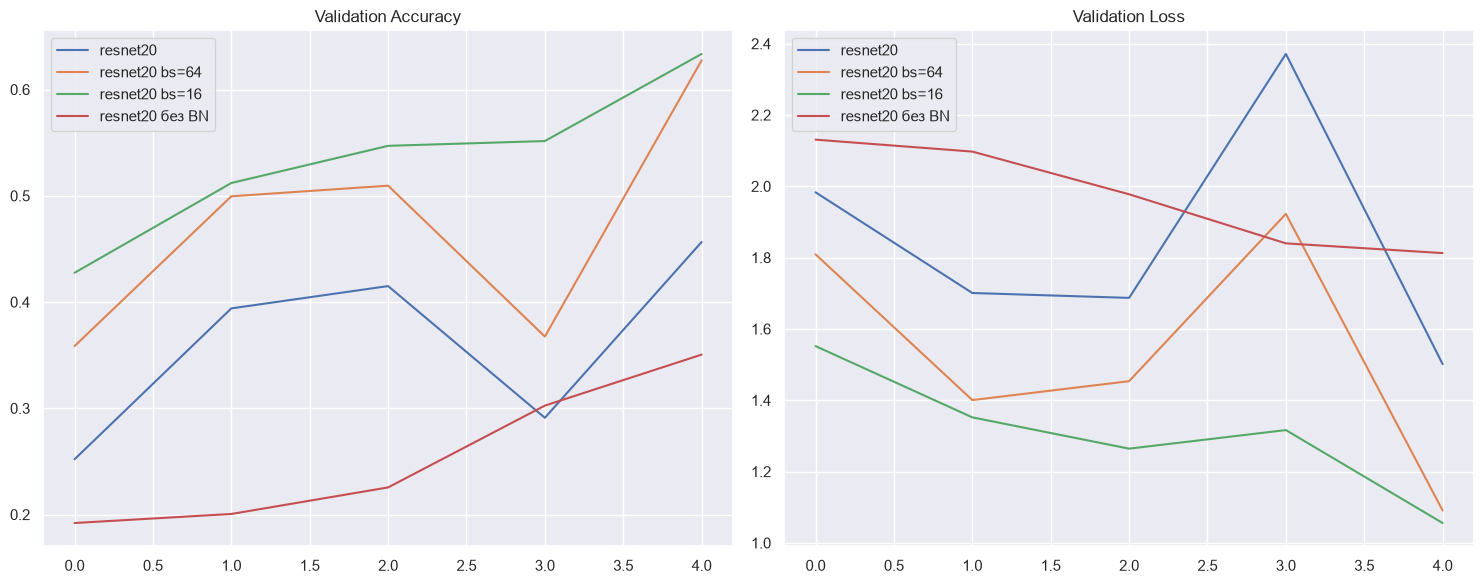

                 параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20           269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20 bs=64     269722.0        0.6275             0.6275          1.0908    0.6155    37.1178
resnet20 bs=16     269722.0        0.6335             0.6335          1.0557    0.6210    52.0649
resnet20 без BN    269722.0        0.3505             0.3505          1.8126    0.3505    30.7514


In [ ]:
run('resnet20 bs=64', resnet20(), batch_size=64)
run('resnet20 bs=16', resnet20(), batch_size=16)
run('resnet20 без BN', ResNet(BasicBlock, [3, 3, 3], use_batch_norm=False))

names = ['resnet20', 'resnet20 bs=64', 'resnet20 bs=16', 'resnet20 без BN']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Відповідь.** Пакетна нормалізація суттєво допомагає навчанню. ResNet20 без пакетної нормалізації дає лише 0.351 на тесті проти 0.467 із нею, а ResNet110 без неї взагалі не навчається (дивись нижче). Нормалізація стабілізує розподіл активацій і дозволяє градієнтам проходити через багато шарів.

Зменшення розміру батча з 256 до 64 різко покращило результат: test accuracy зросла з 0.467 до 0.616 (validation 0.628 проти 0.457). Подальше зменшення до 16 дало ще небагато: 0.621 (validation 0.634), але час епохи зріс з 37 до 52 секунд. Основна причина тут у кількості кроків оптимізатора: за 5 епох на 10 000 зображень батч 256 дає лише 200 оновлень ваг, батч 64 дає 785, а батч 16 дає 3125. Мережа за малу кількість кроків недонавчена, тож більше оновлень дає кращий результат. Крім того, шум градієнта в малих батчах діє як регуляризація. Приріст при переході від 64 до 16 (0.5 п.п.) вже в межах випадкового розкиду, тобто кількість оновлень перестала бути вузьким місцем. Для пакетної нормалізації дуже малі батчі (одиниці зображень) шкідливі: статистики середнього й дисперсії, обчислені за кількома зразками, стають шумними й неточними, тому далі зменшувати батч не варто, і нормалізація працюватиме гірше, а навчання за часом дорожче. Цього ми не перевіряли, це теоретичне пояснення.

# Завдання 8. ResNet110 і пакетна нормалізація

> 8. Реалізуйте ResNet110 (можливо, доведеться зменшити розмір batch'a). Перевірте твердження, що ResNet110 не піддаються навчанню (або навчається в 10% випадків), якщо відключити BatchNorm.

== resnet110


Epoch: 1 Time: 00:03:31 Accuracy: 0.4010


Epoch: 2 Time: 00:07:03 Accuracy: 0.4205


test accuracy: 0.4295
== resnet110_no_bn


Epoch: 1 Time: 00:03:21 Accuracy: 0.1355


Epoch: 2 Time: 00:06:42 Accuracy: 0.1035


test accuracy: 0.1295


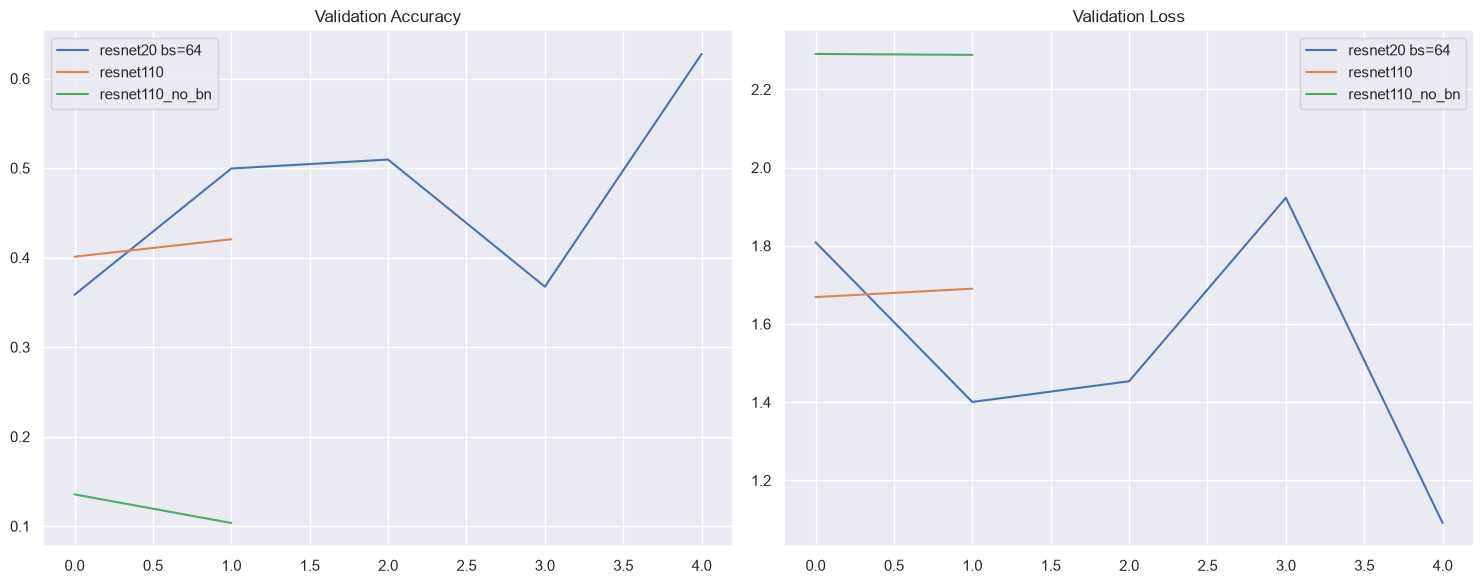

                 параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20 bs=64     269722.0        0.6275             0.6275          1.0908    0.6155    37.1178
resnet110         1727962.0        0.4205             0.4205          1.6686    0.4295   211.9697
resnet110_no_bn   1727962.0        0.1355             0.1035          2.2882    0.1295   201.2587


In [ ]:
run('resnet110', resnet110(), batch_size=64, epoch_num=2, epoch_info_show=1)
run('resnet110_no_bn', resnet110_no_bn(), batch_size=64, epoch_num=2, epoch_info_show=1)

names = ['resnet20 bs=64', 'resnet110', 'resnet110_no_bn']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Відповідь.** Твердження підтверджується. ResNet110 без пакетної нормалізації не навчилась: після 2 епох вона дає test accuracy 0.1295 і validation accuracy 0.1355 (близько 10%, тобто на рівні вгадування серед 10 класів), а валідаційна втрата 2.29 майже дорівнює втраті випадкового вгадування (ln 10 ≈ 2.30). ResNet110 із пакетною нормалізацією навчається: 0.4295 на тесті за ті самі 2 епохи (батч 64). Для порівняння, ResNet20 без пакетної нормалізації теж гірша, але навчається (0.351 за 5 епох), бо вона набагато менш глибока. Тобто що глибша мережа, то критичніша пакетна нормалізація. Через час (ResNet110 навчається близько 3.5 хвилини на епоху на CPU) вона навчалась лише 2 епохи, тому прямо порівнювати її точність з ResNet20 (5 епох) не можна. Перевірено один запуск, тож «в 10% випадків» ми не перевіряли.

# Завдання 9. Dropout та параметр p

> 9. Проаналізуйте результат та зробіть висновки щодо впливу параметру p та шару Dropout взагалі.

== resnet20_d_out p=0.15


Epoch: 1 Time: 00:00:33 Accuracy: 0.1750


Epoch: 2 Time: 00:01:06 Accuracy: 0.2905


Epoch: 3 Time: 00:01:39 Accuracy: 0.3840


Epoch: 4 Time: 00:02:08 Accuracy: 0.4360


Epoch: 5 Time: 00:02:34 Accuracy: 0.4385


... (9 outputs left out)

Epoch: 3 Time: 00:01:17 Accuracy: 0.1285


Epoch: 4 Time: 00:01:43 Accuracy: 0.1045


Epoch: 5 Time: 00:02:09 Accuracy: 0.1335


test accuracy: 0.1260


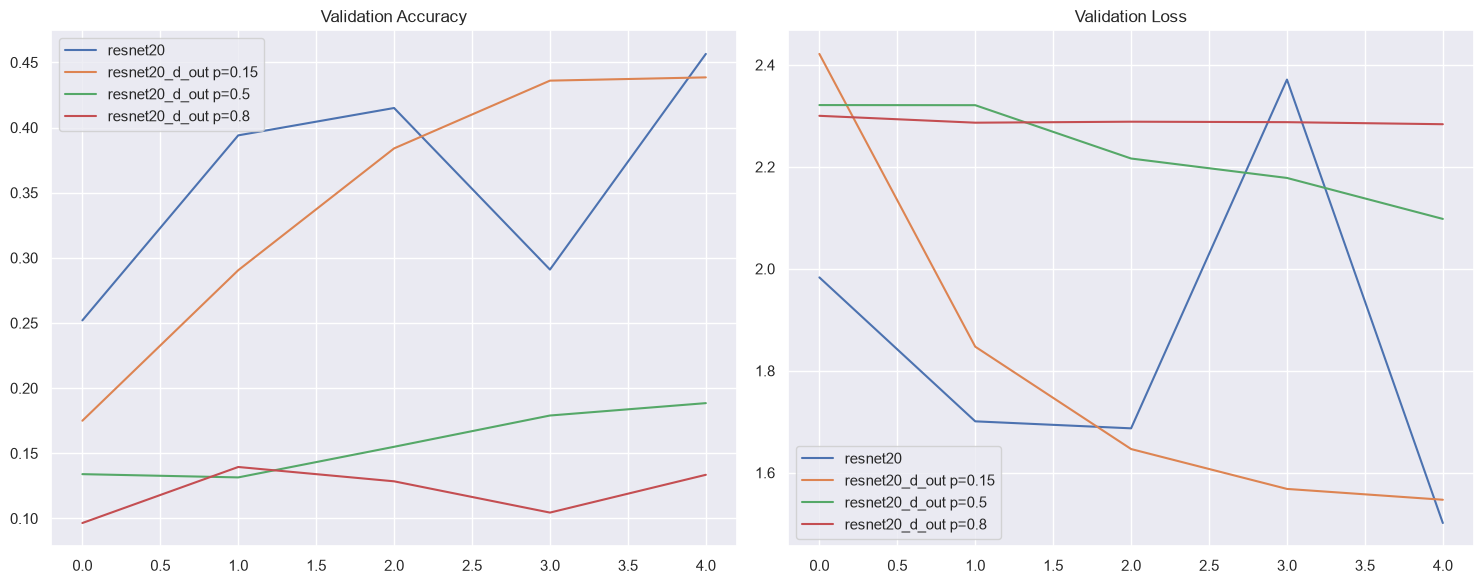

                       параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20                 269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20_d_out p=0.15    269722.0        0.4385             0.4385          1.5469    0.4530    30.8028
resnet20_d_out p=0.5     269722.0        0.1885             0.1885          2.0978    0.2275    25.8808
resnet20_d_out p=0.8     269722.0        0.1395             0.1335          2.2836    0.1260    25.8660


In [ ]:
for p in (0.15, 0.5, 0.8):
    run(f'resnet20_d_out p={p}', resnet20_d_out(p))

names = ['resnet20'] + [f'resnet20_d_out p={p}' for p in (0.15, 0.5, 0.8)]
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Висновок.** Dropout у цих експериментах погіршує результат, і чим більше p, тим гірше: без Dropout test accuracy 0.467, при p=0.15 вона 0.453, при p=0.5 лише 0.228, а при p=0.8 мережа майже нічого не навчилась (0.126). Dropout2d вимикає цілі канали карт ознак після кожного згорткового шару, тому велика частка відключених каналів не дозволяє мережі накопичити інформацію. Dropout є регуляризацією проти перенавчання, а в нас воно ще не виникло: навчання йде всього 5 епох на 10 000 зображень, і мережа недонавчена, тож додаткове ускладнення навчання лише шкодить. Малі значення p (0.15) майже не впливають. Dropout варто використовувати, коли є перенавчання (велика різниця між втратою на тренуванні та валідації) і мережа навчається довго, і підбирати p невеликим (0.1–0.3).

# Завдання 11. L2-регуляризація

> 11. Проаналізуйте, як впливає застосування l2-регуляризації?

== resnet20 wd=0.0001


Epoch: 1 Time: 00:00:26 Accuracy: 0.1985


Epoch: 2 Time: 00:00:51 Accuracy: 0.3110


Epoch: 3 Time: 00:01:17 Accuracy: 0.3855


Epoch: 4 Time: 00:01:43 Accuracy: 0.4080


Epoch: 5 Time: 00:02:09 Accuracy: 0.4235


... (9 outputs left out)

Epoch: 3 Time: 00:01:16 Accuracy: 0.4185


Epoch: 4 Time: 00:01:42 Accuracy: 0.4950


Epoch: 5 Time: 00:02:07 Accuracy: 0.4695


test accuracy: 0.4865


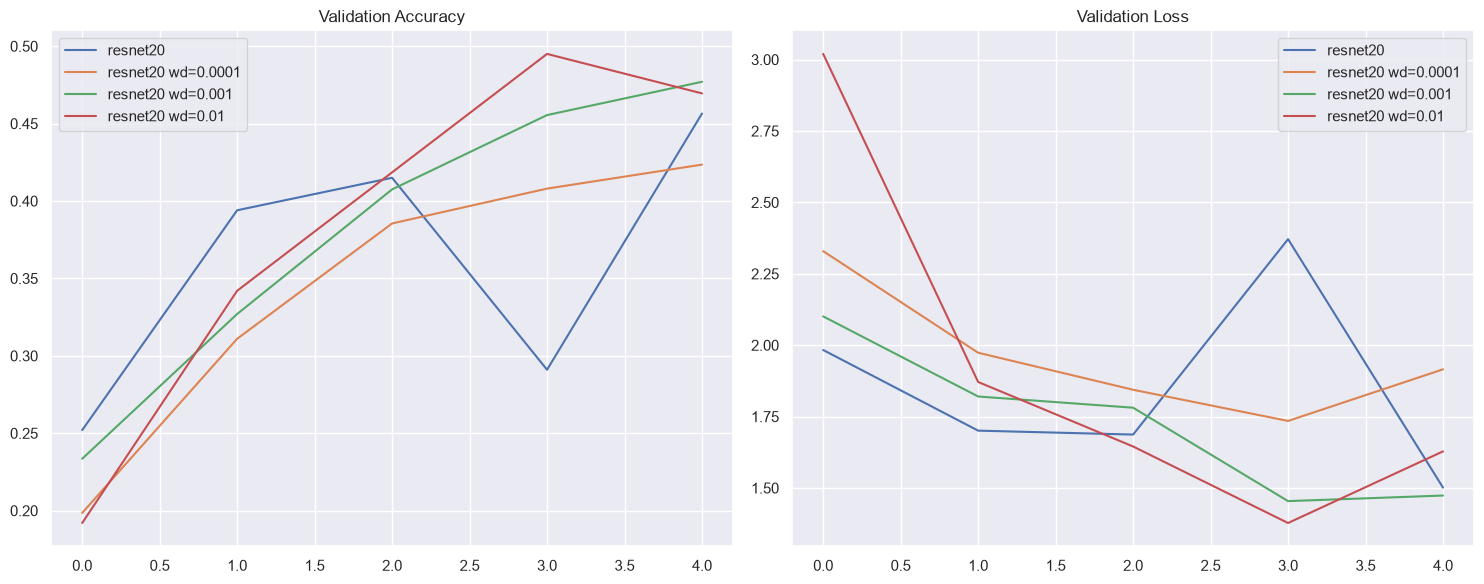

                    параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20              269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20 wd=0.0001    269722.0        0.4235             0.4235          1.7347    0.4195    25.8981
resnet20 wd=0.001     269722.0        0.4770             0.4770          1.4540    0.4970    25.4487
resnet20 wd=0.01      269722.0        0.4950             0.4695          1.3773    0.4865    25.5109


In [ ]:
for wd in (1e-4, 1e-3, 1e-2):
    run(f'resnet20 wd={wd}', resnet20(), weight_decay=wd)

names = ['resnet20'] + [f'resnet20 wd={wd}' for wd in (1e-4, 1e-3, 1e-2)]
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Висновок.** Результати для L2-регуляризації неоднозначні. Без регуляризації test accuracy 0.467, з `weight_decay=1e-4` вона 0.420, з `1e-3` вона 0.497, а з `1e-2` вона 0.487 (validation accuracy 0.4565, 0.4235, 0.477, 0.495). Значення 1e-3 і 1e-2 дали приріст приблизно +2–3 п.п. і зменшили validation loss (1.50 → 1.45 і 1.38), але значення 1e-4 дало гірший результат, ніж без регуляризації, а це не вкладається в очікувану тенденцію. Розкид між запусками однієї архітектури в цій роботі становить близько 4 п.п., тому різниці такого розміру не можна вважати доведеними. Значення 1e-2, яке в теорії радили не ставити, мережі навчитись не завадило. Для надійного висновку потрібно повторювати експерименти на різних seed і навчати довше, коли з'являється перенавчання.

# Завдання 5. Bottleneck у залишкових блоках

> 5. Спробуйте додати bottleneck до residual blocks.

Параметрів: 313114
== resnet20 bottleneck


Epoch: 1 Time: 00:00:43 Accuracy: 0.1955


Epoch: 2 Time: 00:01:26 Accuracy: 0.4060


Epoch: 3 Time: 00:02:08 Accuracy: 0.3710


Epoch: 4 Time: 00:02:50 Accuracy: 0.4735


Epoch: 5 Time: 00:03:32 Accuracy: 0.4865


test accuracy: 0.5065


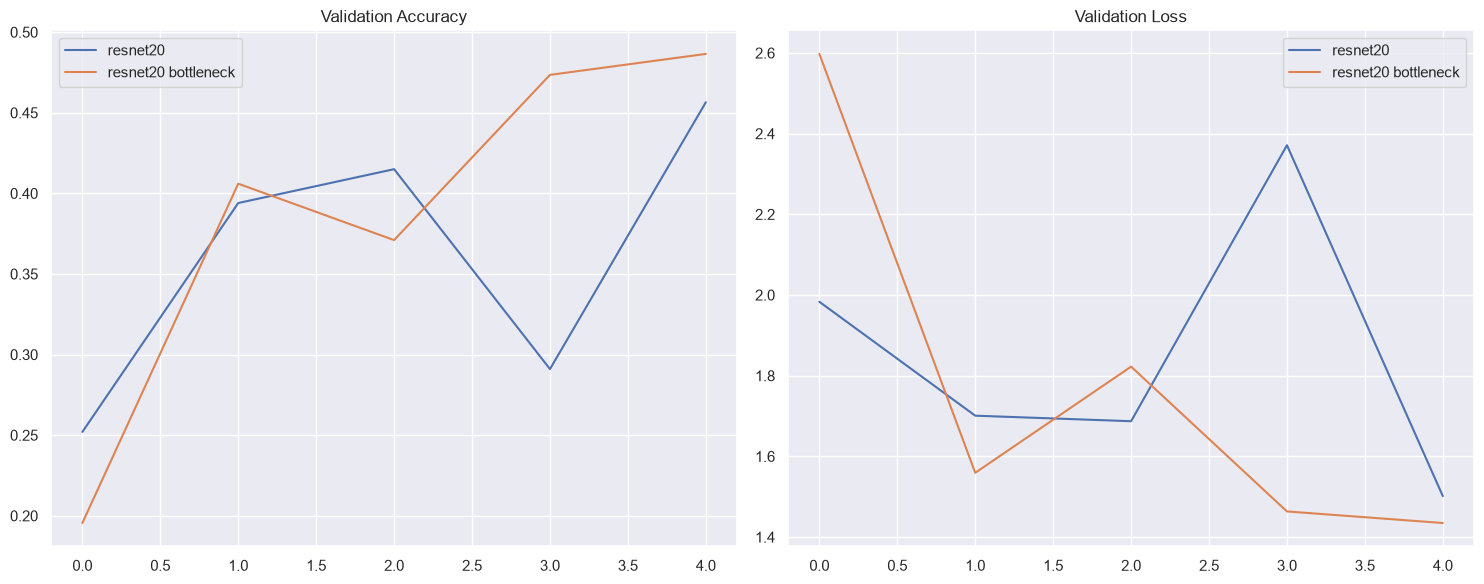

                     параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20               269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20 bottleneck    313114.0        0.4865             0.4865          1.4346    0.5065    42.5818


In [ ]:
class Bottleneck(torch.nn.Module):
    expansion = 4

    def __init__(self, in_planes, planes, stride=1, option='B',
                 use_batch_norm=True, use_drop_out=False, d_out_p=0.5):
        super(Bottleneck, self).__init__()
        self.conv1 = torch.nn.Conv2d(in_planes, planes, kernel_size=1, bias=False)
        self.bn1 = torch.nn.BatchNorm2d(planes)
        self.conv2 = torch.nn.Conv2d(planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn2 = torch.nn.BatchNorm2d(planes)
        self.conv3 = torch.nn.Conv2d(planes, self.expansion * planes, kernel_size=1, bias=False)
        self.bn3 = torch.nn.BatchNorm2d(self.expansion * planes)
        self.act = torch.nn.ReLU()

        self.shortcut = torch.nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = torch.nn.Sequential(
                torch.nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                torch.nn.BatchNorm2d(self.expansion * planes))

    def forward(self, x):
        out = self.act(self.bn1(self.conv1(x)))
        out = self.act(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        out += self.shortcut(x)
        return self.act(out)

def resnet20_bottleneck():
    return ResNet(Bottleneck, [3, 3, 3])

print("Параметрів:", sum(p.numel() for p in resnet20_bottleneck().parameters()))
run('resnet20 bottleneck', resnet20_bottleneck())

names = ['resnet20', 'resnet20 bottleneck']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

**Результат.** Bottleneck-блок (згортка 1 на 1, згортка 3 на 3, згортка 1 на 1 з розширенням каналів у 4 рази, коротке з'єднання через згортку 1 на 1) у ResNet20 дає test accuracy 0.507 проти 0.467 у звичайного блоку (validation 0.487 проти 0.457), validation loss 1.43 проти 1.50. Мережа трохи більша (313 тис. проти 270 тис. параметрів) і повільніша (43 с проти 33 с на епоху), бо вихідні канали блоку в 4 рази ширші. Приріст 4 п.п. сумірний із розкидом між запусками, тому однозначно стверджувати перевагу не можна, але він узгоджується з ідеєю bottleneck: стиснути канали перед дорогою згорткою 3 на 3 і потім розширити, щоб отримати глибшу чи ширшу мережу без значного зростання складності.

# Завдання 2. Власні оптимізації: аугментація та ансамбль

> 2. Спробуйте власні оптимізації, спробуйте покращити результат: модифікуйте архітектуру, додайте аугментацію, можете створити ансамбль із декількох мереж, тощо.

== resnet20 + аугментація


Epoch: 1 Time: 00:00:26 Accuracy: 0.1930


Epoch: 2 Time: 00:00:51 Accuracy: 0.2890


Epoch: 3 Time: 00:01:17 Accuracy: 0.4165


Epoch: 4 Time: 00:01:44 Accuracy: 0.4010


Epoch: 5 Time: 00:02:09 Accuracy: 0.5410


test accuracy: 0.5520


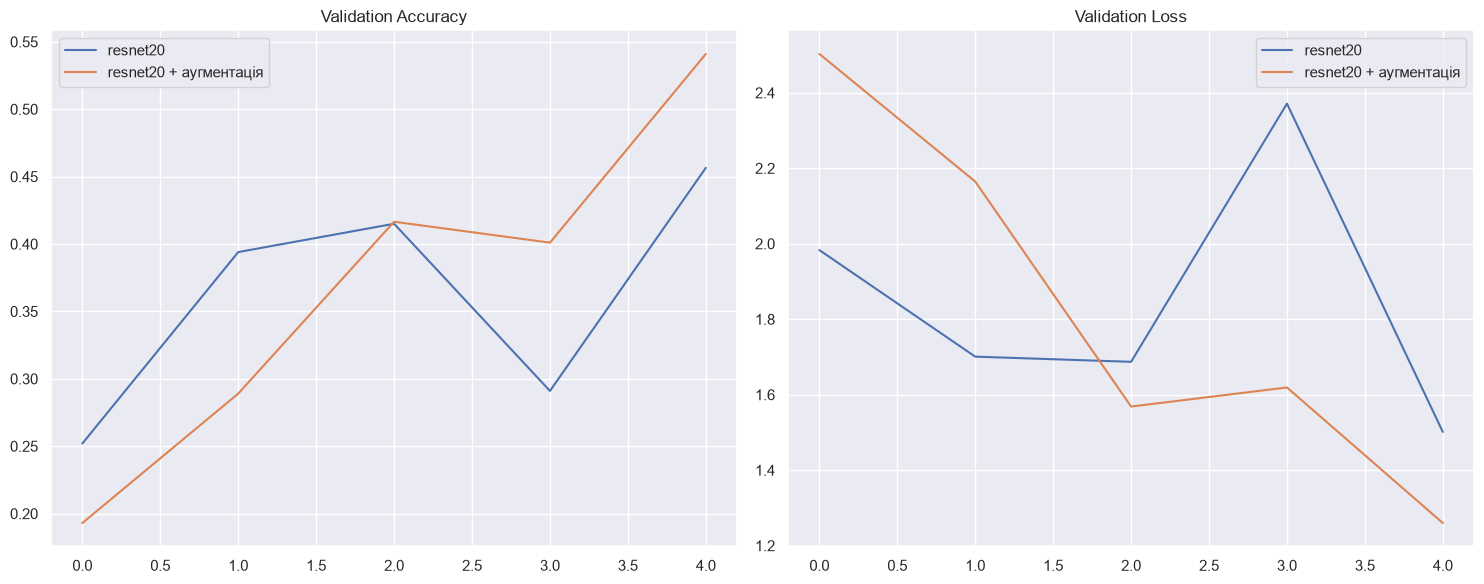

                        параметрів  best val acc  val acc (остання)  val loss (мін)  test acc  с / епоху
resnet20                  269722.0        0.4565             0.4565          1.5013    0.4665    32.6309
resnet20 + аугментація    269722.0        0.5410             0.5410          1.2599    0.5520    25.8965


In [ ]:
run('resnet20 + аугментація', resnet20(), augment=True)

names = ['resnet20', 'resnet20 + аугментація']
acc_loss_graph(accuracies, losses, names)
print(results_table(names).round(4).to_string())

Аугментація складається з випадкового відображення кожного зображення по горизонталі та випадкового зсуву (кадрування з відступом 4 пікселі) для кожного батча.

In [ ]:
def ensemble_accuracy(names):
    probs = torch.stack([torch.softmax(finals[n]['logits'], dim=1) for n in names]).mean(dim=0)
    return (probs.argmax(dim=1) == y_test).float().mean().item()

ensembles = {
    'resnet20 + resnet20 bs=64': ['resnet20', 'resnet20 bs=64'],
    'три ResNet20 (звичайна, bs=64, аугментація)': ['resnet20', 'resnet20 bs=64', 'resnet20 + аугментація'],
    'ResNet20 різних типів + resnet18': ['resnet20', 'resnet20 bs=64', 'resnet20 + аугментація', 'resnet18'],
}

rows = {'одна resnet20': finals['resnet20']['test acc'], 'resnet20 + аугментація': finals['resnet20 + аугментація']['test acc']}
for title, members in ensembles.items():
    rows[title] = ensemble_accuracy(members)

print(pd.Series(rows, name='test acc').round(4).to_string())

одна resnet20                                  0.4665
resnet20 + аугментація                         0.5520
resnet20 + resnet20 bs=64                      0.6170
три ResNet20 (звичайна, bs=64, аугментація)    0.6350
ResNet20 різних типів + resnet18               0.6215


**Результат.** Аугментація дала найбільший приріст серед змін, які ми спробували над звичайним навчанням ResNet20: test accuracy зросла з 0.467 до 0.552 (validation 0.457 → 0.541), а validation loss зменшилась з 1.50 до 1.26. Дзеркальне відображення і зсуви збільшують різноманітність навчальних зображень, що для малої вибірки з 10 000 зображень особливо корисно. Ансамбль усереднює ймовірності класів кількох мереж: ансамбль із двох ResNet20 (батч 256 та 64) дає 0.617, а ансамбль із трьох мереж (звичайна, батч 64, аугментація) дає 0.635, що краще за кожну окрему мережу з цього набору (0.467, 0.616, 0.552), але лише трохи краще за найкращу окрему мережу (0.616). Додавання ResNet18 до ансамблю точність не покращило (0.622). Ансамбль працює, коли помилки мереж різні, і не допомагає, коли одна з мереж значно слабша за інші.

# Завдання 3. Найкраще рішення для CIFAR10

> 3. Спробуйте знайти краще рішення для датасету CIFAR10, яка мережа повинна бути використана.

In [ ]:
single_names = [n for n in finals if n not in ('resnet110_no_bn',)]
summary = results_table(single_names)[['параметрів', 'best val acc', 'test acc', 'с / епоху']]
summary = summary.sort_values('best val acc', ascending=False)
print(summary.round(4).to_string())

best_name = summary.index[0]
print()
print("Найкраща одиночна мережа за валідацією:", best_name, "| test acc:", round(finals[best_name]['test acc'], 4))
print("Найкращий ансамбль:", round(max(rows.values()), 4))

                        параметрів  best val acc  test acc  с / епоху
resnet20 bs=16            269722.0        0.6335    0.6210    52.0649
resnet20 bs=64            269722.0        0.6275    0.6155    37.1178
cifar_net                1090384.0        0.5835    0.5975     3.1784
resnet20 + аугментація    269722.0        0.5410    0.5520    25.8965
resnet20 (власна)         269722.0        0.5045    0.4260    32.6172
resnet20 wd=0.01          269722.0        0.4950    0.4865    25.5109
resnet20 bottleneck       313114.0        0.4865    0.5065    42.5818
resnet18                11181642.0        0.4775    0.4610    67.3609
resnet20 wd=0.001         269722.0        0.4770    0.4970    25.4487
resnet20                  269722.0        0.4565    0.4665    32.6309
resnet20_d_out p=0.15     269722.0        0.4385    0.4530    30.8028
resnet34                21289802.0        0.4380    0.4585    79.0096
resnet20 wd=0.0001        269722.0        0.4235    0.4195    25.8981
resnet110           

**Відповідь.** Серед усіх запущених у цій роботі варіантів найвищу точність на валідації має ResNet20 із батчем 16 (0.634, test 0.621), а за нею ResNet20 з батчем 64 (0.628, test 0.616), CIFARNet (0.584, test 0.598) і ResNet20 з аугментацією (0.541, test 0.552). Найкращий результат дав ансамбль із трьох мереж ResNet20: 0.635 на тесті. Для CIFAR10 слід використовувати мережу, створену саме для малих зображень (ResNet20 або подібну CIFARNet), а не ImageNet-мережі (ResNet18/34), які мають у 40–80 разів більше параметрів і працюють гірше. Для цих умов найважливіше було вибрати правильні гіперпараметри навчання (малий батч, аугментація, пакетна нормалізація), а не збільшувати глибину мережі. При навчанні довше та на повних даних ранжування може змінитись: глибші залишкові мережі виграють, коли даних і епох достатньо. Ця таблиця показує вплив лише в умовах швидких експериментів на підвибірці, одним запуском.

# Висновки

У цьому практикумі ми ознайомились з архітектурами згорткових мереж (CIFARNet, ResNet18, ResNet34, ResNet20, ResNet110), реалізували залишковий блок із коротким з'єднанням та блок bottleneck, перевірили вплив пакетної нормалізації, розміру батча, Dropout і L2-регуляризації та вивчили концепцію transfer learning. Метою завдання було ознайомитись з архітектурами згорткових нейронних мереж та засвоїти концепцію transfer learning, і її досягнуто. Усі експерименти проводились на підвибірці CIFAR10 (10 000 зображень для навчання) по 5 епох одним запуском, тому різниці менше за 4–5 п.п. між мережами не є надійними: одна й та сама архітектура ResNet20 у двох запусках дала 0.467 та 0.426.

**Вибір оптимальної мережі.** Найкращий результат серед одиночних мереж дала ResNet20 із малим батчем (test accuracy 0.621 для батча 16 і 0.616 для батча 64), далі CIFARNet (0.598), що навчається у 10 разів швидше, ResNet20 з аугментацією (0.552) та з bottleneck (0.507). Ансамбль із трьох ResNet20 дав 0.635. ImageNet-версії ResNet18 і ResNet34 з 11 і 21 млн параметрів дали лише 0.461 і 0.459, тобто для малих зображень CIFAR10 кращі спеціалізовані мережі. Глибина мережі сама по собі нічого не дала: ResNet110 за 2 епохи дала 0.430.

**Гіперпараметри.** Пакетна нормалізація критично важлива: без неї ResNet20 дає 0.351 замість 0.467, а ResNet110 не навчається взагалі (0.13, тобто вгадування). Зменшення батча з 256 до 64 підняло точність з 0.467 до 0.616, головним чином через те, що за ту саму кількість епох зростає кількість кроків оптимізатора (з 200 до 785); подальше зменшення до 16 дало лише +0.5 п.п. за вищої вартості. Dropout2d погіршує результат, особливо при великих p (0.5 і 0.8 майже не навчаються), бо мережа ще не перенавчена. L2-регуляризація при 1e-3 і 1e-2 дала +2–3 п.п., але значення 1e-4 погіршило результат, тому висновок невпевнений. Найбільше допомогла аугментація (+8.5 п.п.) і, меншою мірою, bottleneck-блок (+4 п.п.).

**Transfer learning.** У цій роботі всі мережі навчались з нуля. Концепція transfer learning (використання ваг мережі, попередньо навченої на великому наборі даних, заміна останнього шару на новий і донавчання всіх або лише останніх шарів) використана в роботах №13 та №14.

# Контрольні питання

**1. Що таке transfer learning і для чого він використовується?**

Transfer learning використовує накопичений при вирішенні однієї задачі досвід для розв'язання іншої, схожої. Нейромережу спочатку навчають на великому наборі даних, а потім донавчають на цільовому. Це потрібно, бо глибокі мережі потребують великих обсягів даних, а в конкретній задачі даних часто недостатньо, щоб добре натренувати всі шари. Передбачені готові архітектури (AlexNet, VGG, Inception, ResNet) можна використовувати як чорний ящик. Якщо кількість класів у цільовому наборі інша, останній шар видаляють і ставлять новий із потрібною кількістю виходів, ініціалізований випадковими вагами, а ваги решти шарів завантажують із попередньо навченої моделі. Є дві стратегії: end-to-end, коли тренують усю мережу або вибіркові шари, не фіксуючи попередньо навчені ваги (тонке налаштування, fine-tuning), і використання попередньо навченої моделі як екстрактора ознак, коли тренують лише змінений останній повнозв'язний шар.

**2. У чому полягає ідея залишкового навчання (residual learning) та архітектури ResNet?**

Із збільшенням глибини звичайної мережі точність спочатку зростає, а потім швидко погіршується, тобто не всі мережі легко оптимізувати. У ResNet пропонується не сподіватись, що кілька шарів безпосередньо відповідають бажаному відображенню H(x), а явно дозволити їм відповідати залишковому відображенню F(x) = H(x) - x. Тоді початкове відображення дорівнює F(x) + x і реалізується короткими з'єднаннями (shortcut connections), які пропускають один або кілька шарів і додають вхід до виходу блоку. Оптимізувати залишкове відображення простіше: якщо шар не потрібен, достатньо встановити F(x) = 0. Базовий блок має два згорткові шари 3 на 3 з однаковою кількістю каналів, після кожного йде пакетна нормалізація, а ReLU застосовується після додавання входу. Коли розмірність змінюється, коротке з'єднання або доповнює нулями (без додаткових параметрів), або використовує згортку 1 на 1. Назви ResNet18, 34, 50, 101, 152 вказують кількість шарів, а для CIFAR10 є ResNet20, 32, 44, 56, 110, 1202.